# Mind the Stability Gap, Part 2
### Does structure or composition change the picture, and can a better model do better?

**Author:** James Fox · Intro to AI & Machine Learning, Fall 2026

[Part 1](perovskite_stability_gap.ipynb) found that published perovskite lifetimes depend more on *how* a cell was tested than on *what* it was made of, and that a random forest could barely predict lifetime for papers it hadn't seen (R² ≈ 0.12). This notebook asks two follow-up questions:

1. **Split by structure and composition:** do device geometry, dimensionality, cations, halides, the metal, or the hole-transport layer change lifetimes when the test conditions are held fixed?
2. **Improve the numbers:** how much of the model's weakness can better features or better statistics fix, and how much needs better data?

Sections 1–3 repeat Part 1's setup and cleaning exactly, so this notebook runs on its own in Colab.

## 1. Setup

In [1]:
# Two extra libraries for survival analysis (Colab doesn't include them by default)
%pip install -q lifelines scikit-survival

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Standard data-science stack; everything here comes pre-installed in Google Colab.
import os, re, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)

# Chart style: quiet axes and gridlines so the data does the talking
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ab"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 11, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
SOURCE = "Source: The Perovskite Database (Jacobsson et al., Nature Energy 2022), CC BY 4.0"
thousands = lambda v, _: f"{v/1000:g}K" if v >= 1000 else f"{v:.0f}"

pct = lambda share: f"{share:.0%}" if share >= 0.005 else "<1%"

def save(fig, name):
    # Saves each chart as a high-resolution PNG in figures/ (ready for LinkedIn)
    fig.savefig(f"figures/{name}.png")
    plt.show()

def hbars(ax, labels, values, fmt, color=BLUE, pad=0.01, span=None):
    # Horizontal bars, top-to-bottom in the order given, with the value printed at each bar's tip
    y = np.arange(len(values))[::-1]
    ax.barh(y, values, height=0.55, color=color)
    span = span or (max(values) if max(values) > 0 else 1)
    for yi, v in zip(y, values):
        ax.text(v + span * pad, yi, fmt(v), va="center", fontsize=10, color=INK_2)
    ax.set_yticks(y, labels)
    ax.set_xlim(0, span * 1.3)
    ax.grid(axis="y", visible=False)

In [3]:
from lifelines import KaplanMeierFitter
from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sklearn.metrics import r2_score

## 2. Get the data

In [4]:
DATA_URL = ("https://zenodo.org/records/5837035/files/"
            "Jesperkemist/perovskitedatabase_data-v1.0.1.zip?download=1")
ZIP_PATH = "perovskitedatabase_data-v1.0.1.zip"
CSV_NAME = "Perovskite_database_content_all_data.csv"

if not os.path.exists(ZIP_PATH):
    print("Downloading the Perovskite Database snapshot from Zenodo (about 3 MB)...")
    try:
        urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    except Exception as err:
        raise RuntimeError(
            f"Download failed ({err}). Open this link in your browser:\n{DATA_URL}\n"
            "then drag the zip into Colab's Files panel (folder icon, left side) and re-run this cell.")

with zipfile.ZipFile(ZIP_PATH) as zf:
    member = next(name for name in zf.namelist() if name.endswith(CSV_NAME))
    raw = pd.read_csv(zf.open(member), low_memory=False)

print(f"Loaded {len(raw):,} devices x {raw.shape[1]} columns")
raw[["Ref_DOI_number", "Ref_publication_date", "Cell_architecture",
     "Perovskite_composition_short_form", "JV_default_PCE", "Stability_measured"]].head()

Loaded 42,443 devices x 410 columns


,Ref_DOI_number,Ref_publication_date,Cell_architecture,Perovskite_composition_short_form,JV_default_PCE,Stability_measured
0,10.1021/jp5126624,2015-01-06,nip,CsSnI,0.00,False
1,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.00,False
2,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.13,False
3,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.12,False
4,10.1021/jp5126624,2015-01-06,nip,CsSnBr,0.10,False


## 3. Clean it up (same as Part 1)

In [5]:
MISSING = {"", "nan", "none", "unknown", "n/a", "na", "-"}

def get(name):
    # Returns a column, or an all-empty column if this snapshot doesn't have it
    return raw[name] if name in raw.columns else pd.Series(np.nan, index=raw.index)

def reported(series):
    # True where a cell holds real information rather than one of the 'missing' markers
    def check(v):
        if pd.isna(v):
            return False
        return any(tok.strip().lower() not in MISSING for tok in re.split(r"[;|>]+", str(v)))
    return series.map(check).astype(bool)

def to_bool(series):
    return series.astype(str).str.strip().str.lower().isin(["true", "1", "yes"])

def to_num(series):
    # Numbers stay numbers; text like '1.6 | nan' falls back to its first number
    direct = pd.to_numeric(series, errors="coerce")
    first = pd.to_numeric(series.astype(str).str.extract(r"(-?\d+(?:\.\d+)?)")[0], errors="coerce")
    return direct.fillna(first)

def range_max(series):
    # Largest number in a 'min; max' range ('25; 85' -> 85)
    def f(v):
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(v))
        return max(map(float, nums)) if nums else np.nan
    return series.map(f)

def text(series):
    return series.where(reported(series), "").astype(str).str.strip().str.lower()

def atmosphere_group(v):
    tokens = {t.strip() for t in re.split(r"[;|]", v) if t.strip()}
    if not tokens:
        return "Not reported"
    if tokens <= {"n2", "ar", "argon", "vacuum", "he", "inert"}:
        return "Inert (N2/Ar/vacuum)"
    if "dry air" in tokens:
        return "Dry air"
    if tokens & {"air", "ambient"}:
        return "Air / ambient"
    return "Other"

def bias_group(v):
    if not v:
        return "Not reported"
    for key, label in [("mpp", "MPP tracking"), ("open", "Open circuit"),
                       ("short", "Short circuit"), ("constant", "Constant bias")]:
        if key in v:
            return label
    return "Other"

TEST_TYPES = {  # ISOS category -> plain-English test type (conditions from Khenkin et al. 2020, Table 1)
    "d1": "Dark, room temperature (shelf life)",
    "d2": "Dark, heated to 65-85 °C",
    "d3": "Dark, 65-85 °C and 85% humidity (damp heat)",
    "l1": "Under light, room temperature",
    "l2": "Under light, heated to 65-85 °C",
    "l3": "Under light, heated, ~50% humidity",
    "o":  "Outdoors",
}
def test_type(v):
    v = v.replace("‐", "-").replace("‑", "-").replace(" ", "")   # some entries use unicode hyphens
    if not v:
        return "Not classified"
    m = re.match(r"isos-(lc|[dlotv])-?(\d)", v)
    if not m:
        return "Cycling, bias, IEC or other"
    kind = m.group(1) if m.group(1) == "o" else m.group(1) + m.group(2)
    return TEST_TYPES.get(kind, "Cycling, bias, IEC or other")

In [6]:
df = pd.DataFrame(index=raw.index)

# Who published it, and when
doi = text(get("Ref_DOI_number"))
df["paper"] = np.where(doi != "", doi, "no-doi-" + get("Ref_ID").astype(str))
df["year"] = pd.to_numeric(get("Ref_publication_date").astype(str)
                           .str.extract(r"((?:19|20)\d{2})")[0], errors="coerce")

# The device
df["architecture"] = text(get("Cell_architecture")).replace("", "not reported")
top_comps = text(get("Perovskite_composition_short_form")).value_counts().head(12).index
df["composition"] = text(get("Perovskite_composition_short_form")).where(lambda s: s.isin(top_comps), "other")
df["band_gap"] = to_num(get("Perovskite_band_gap")).where(lambda s: s.between(0.5, 4))
df["area_cm2"] = to_num(get("Cell_area_measured")).where(lambda s: s > 0)
df["pce"] = to_num(get("JV_default_PCE")).where(lambda s: s > 0)
df["encapsulated"] = to_bool(get("Encapsulation"))
df["module"] = to_bool(get("Module"))
df["outdoor"] = to_bool(get("Outdoor_tested"))

# The stability test
df["stability_tested"] = to_bool(get("Stability_measured"))
df["t80"] = to_num(get("Stability_PCE_T80")).where(lambda s: s > 0)
df["end_pct"] = to_num(get("Stability_PCE_end_of_experiment")).where(lambda s: s >= 0)
df["pce_initial"] = to_num(get("Stability_PCE_initial_value")).where(lambda s: s > 0).fillna(df["pce"])
df["duration_h"] = to_num(get("Stability_time_total_exposure")).where(lambda s: s > 0)
df["light_mw"] = to_num(get("Stability_light_intensity")).where(lambda s: s >= 0)
df["temp_max_c"] = range_max(get("Stability_temperature_range"))
df["rh_pct"] = to_num(get("Stability_relative_humidity_average_value")).fillna(
    range_max(get("Stability_relative_humidity_range")))
df["atmosphere"] = text(get("Stability_atmosphere")).map(atmosphere_group)
df["bias"] = text(get("Stability_potential_bias_load_condition")).map(bias_group)
dark = text(get("Stability_light_source_type")).str.contains("dark") | (df["light_mw"] == 0)
df["light_condition"] = np.select([dark, df["light_mw"] > 0], ["Dark", "Illuminated"], "Not reported")
df["test_type"] = text(get("Stability_protocol")).map(test_type)

tested = df[df["stability_tested"]]
print(f"{len(df):,} devices from {df['paper'].nunique():,} papers")
print(f"{len(tested):,} devices ({len(tested)/len(df):.1%}) have some kind of stability test")

42,443 devices from 7,358 papers
7,419 devices (17.5%) have some kind of stability test


## 4. Group devices by structure and composition

Each device gets a label in six groupings. Groups with very few devices are folded into "Other."

| Grouping | What it captures |
|---|---|
| **Geometry** | Device stack: n-i-p with a mesoporous scaffold, n-i-p planar, or p-i-n ("inverted") |
| **Dimensionality** | 3D perovskite, 3D with a 2D capping layer, 2D/3D mixture, layered 2D, or quantum dots (0D) |
| **A-site cation** | MA only, FA only, Cs only (all-inorganic), or mixtures |
| **Halide** | Iodide only, bromide only, mixed Br/I, or chloride-containing |
| **Metal (B-site)** | Lead, tin, lead-tin, or lead-free |
| **Hole-transport layer** | Spiro-OMeTAD, PEDOT:PSS, PTAA, NiOx, P3HT, CuSCN, none |

In [7]:
def toks(s):
    return {t.strip().strip("()") for t in re.split(r"[;|]", s) if t.strip()}

flag = lambda name: to_bool(get(name))
df["dimensionality"] = np.select(
    [flag("Perovskite_dimension_3D_with_2D_capping_layer"), flag("Perovskite_dimension_2D3D_mixture"),
     flag("Perovskite_dimension_2D") & ~flag("Perovskite_dimension_3D"), flag("Perovskite_dimension_0D"),
     flag("Perovskite_dimension_3D")],
    ["3D with 2D capping layer", "2D/3D mixture", "2D (layered)", "0D (quantum dots)", "3D"], "Other")

etl, arch = text(get("ETL_stack_sequence")), text(get("Cell_architecture"))
df["geometry"] = np.select([arch.eq("pin"), arch.eq("nip") & etl.str.contains("-mp"), arch.eq("nip")],
                           ["p-i-n (inverted)", "n-i-p mesoporous", "n-i-p planar"], "Other")

A_FAMILIES = {frozenset({"MA"}): "MA only", frozenset({"FA"}): "FA only", frozenset({"CS"}): "Cs only (all-inorganic)",
              frozenset({"FA", "MA"}): "FA + MA", frozenset({"CS", "FA"}): "Cs + FA",
              frozenset({"CS", "FA", "MA"}): "Cs + FA + MA (triple cation)"}
df["a_site"] = text(get("Perovskite_composition_a_ions")).map(
    lambda s: A_FAMILIES.get(frozenset(x.upper() for x in toks(s)), "Other" if s else "Not reported"))

def halide(s):
    t = {x.capitalize() for x in toks(s)}
    if not t: return "Not reported"
    if "Cl" in t: return "Contains Cl"
    return {frozenset({"I"}): "Iodide only", frozenset({"Br"}): "Bromide only",
            frozenset({"Br", "I"}): "Mixed Br/I"}.get(frozenset(t), "Other")
df["halide"] = text(get("Perovskite_composition_c_ions")).map(halide)

def metal(s):
    t = {x.capitalize() for x in toks(s)}
    if not t: return "Not reported"
    if t == {"Pb"}: return "Lead"
    if t == {"Sn"}: return "Tin"
    if t == {"Pb", "Sn"}: return "Lead-tin"
    return "Lead + other metal" if "Pb" in t else "Lead-free (Bi, Sb, ...)"
df["b_site"] = text(get("Perovskite_composition_b_ions")).map(metal)

htl1 = text(get("HTL_stack_sequence")).str.split("|").str[0].str.strip()
df["htl"] = np.select(
    [htl1.str.startswith("spiro"), htl1.eq("pedot:pss"), htl1.eq("ptaa"),
     htl1.str.startswith("nio") | htl1.str.startswith("nimg"), htl1.eq("p3ht"), htl1.eq("cuscn"), htl1.eq("none")],
    ["Spiro-OMeTAD", "PEDOT:PSS", "PTAA", "NiOx", "P3HT", "CuSCN", "None"], "Other")

# Was the test run in inert gas? (ISOS labels ending in 'I', e.g. ISOS-D-1I)
protocol = text(get("Stability_protocol")).str.replace("‐", "-", regex=False).str.replace(" ", "", regex=False)
df["inert_test"] = protocol.str.match(r"isos-[a-z]+-?\d+i$")

GROUPINGS = {"geometry": "Geometry", "dimensionality": "Dimensionality", "a_site": "A-site cation",
             "halide": "Halide", "b_site": "Metal (B-site)", "htl": "Hole-transport layer"}
for col, name in GROUPINGS.items():
    print(f"{name}: " + ", ".join(f"{k} {v:,}" for k, v in df[col].value_counts().items()))

Geometry: n-i-p planar 15,828, n-i-p mesoporous 13,799, p-i-n (inverted) 12,764, Other 52
Dimensionality: 3D 40,885, 2D (layered) 999, 3D with 2D capping layer 190, 0D (quantum dots) 186, 2D/3D mixture 130, Other 53
A-site cation: MA only 28,608, FA + MA 3,987, Cs + FA + MA (triple cation) 3,823, Cs only (all-inorganic) 2,096, Other 1,824, Cs + FA 1,087, FA only 989, Not reported 29
Halide: Iodide only 32,052, Mixed Br/I 9,274, Bromide only 954, Other 79, Contains Cl 79, Not reported 5
Metal (B-site): Lead 40,653, Tin 635, Lead-tin 504, Lead-free (Bi, Sb, ...) 431, Lead + other metal 215, Not reported 5
Hole-transport layer: Spiro-OMeTAD 21,111, Other 8,292, PEDOT:PSS 6,930, NiOx 2,881, PTAA 2,061, P3HT 921, CuSCN 247


## 5. A fair way to compare lifetimes: survival curves

Part 1 showed two traps in comparing lifetimes:
- **Different tests.** Dark storage gives roughly 3× longer lifetimes than light soaking. So this notebook compares groups **within the same test**: dark room-temperature storage in air (ISOS-D-1) and light soaking at room temperature in air (ISOS-L-1).
- **Censoring.** Averaging only the reported T80s leaves out every device that outlasted its test, which biases lifetimes downward.

The fix for censoring is the **Kaplan–Meier survival curve**, the standard tool in medical trials for estimating median survival when some patients are still alive at the end of the study. Every stability-tested device contributes one of three things:

| What the paper reported | How it's used |
|---|---|
| A T80 | The device "failed" at that time |
| Still at 80% or above when the test ended | Survived *at least* this long (censored) |
| Below 80% at the end, but no T80 | Failed at an estimated time, assuming a straight-line decline from 100% to the final value |

The **median lifetime** is the time at which half the devices in a group have dropped below 80% of their starting efficiency. If more than half outlasted their tests, the median is "not reached."

In [8]:
tested = df[df["stability_tested"]].copy()
straight_line = tested["duration_h"] * 20 / (100 - tested["end_pct"]).clip(lower=20)
tested["time"] = np.select([tested["t80"].notna(), tested["end_pct"].ge(80), tested["end_pct"].lt(80)],
                           [tested["t80"], tested["duration_h"], straight_line], np.nan)
tested["event"] = np.select([tested["t80"].notna(), tested["end_pct"].ge(80), tested["end_pct"].lt(80)],
                            [1, 0, 1], 0).astype(bool)
tested["outcome_source"] = np.select([tested["t80"].notna(), tested["end_pct"].ge(80), tested["end_pct"].lt(80)],
                                     ["reported T80", "outlasted test (censored)", "straight-line estimate"], "none")
surv = tested[tested["time"].gt(0)].copy()
print(f"{len(surv):,} of {len(tested):,} tested devices usable for survival analysis:")
print(surv["outcome_source"].value_counts().to_string())

SHELF = surv["test_type"].eq(TEST_TYPES["d1"]) & ~surv["inert_test"]
LIGHT = surv["test_type"].eq(TEST_TYPES["l1"]) & ~surv["inert_test"]
print(f"\nDark storage in air: {SHELF.sum():,} devices · Light soaking in air: {LIGHT.sum():,} devices")

MIN_N = 25   # don't estimate a median from fewer devices than this
def median_life(sub):
    if len(sub) < MIN_N:
        return np.nan, np.nan, len(sub)
    km = KaplanMeierFitter().fit(sub["time"], sub["event"])
    return km.median_survival_time_, sub["time"].max(), len(sub)

7,358 of 7,419 tested devices usable for survival analysis:
outcome_source
outlasted test (censored)    3123
straight-line estimate       2403
reported T80                 1832

Dark storage in air: 3,887 devices · Light soaking in air: 879 devices


In [9]:
def fmt_life(m, tmax, n):
    if np.isnan(m): return f"too few (n={n})"
    if np.isinf(m): return f"not reached (n={n})"
    return f"{m:,.0f} h (n={n})"

tables, plot_rows = {}, []
for col, name in GROUPINGS.items():
    rows = []
    for group, members in df.groupby(col):
        if group in ("Other", "Not reported"):
            continue
        t_members = surv[surv[col] == group]
        shelf = median_life(t_members[SHELF.loc[t_members.index]])
        light = median_life(t_members[LIGHT.loc[t_members.index]])
        tested_members = members[members["stability_tested"]]
        rows.append({name: group, "Devices": len(members),
                     "Stability-tested": f"{members['stability_tested'].mean():.0%}",
                     "Tests under light": f"{tested_members['light_condition'].eq('Illuminated').mean():.0%}" if len(tested_members) else "–",
                     "Median lifetime, dark storage (air)": fmt_life(*shelf),
                     "Median lifetime, light soaking (air)": fmt_life(*light)})
        if np.isfinite(shelf[0]) and np.isfinite(light[0]):
            plot_rows.append({"section": name, "group": group, "dark": shelf[0], "light": light[0]})
    tables[name] = pd.DataFrame(rows).sort_values("Devices", ascending=False).set_index(name)

for name, table in tables.items():
    display(table.style.format({"Devices": "{:,}"}))

,Devices,Stability-tested,Tests under light,"Median lifetime, dark storage (air)","Median lifetime, light soaking (air)"
Geometry,,,,,
n-i-p planar,"15,828",18%,23%,590 h (n=1548),70 h (n=290)
n-i-p mesoporous,"13,799",18%,25%,900 h (n=1327),182 h (n=309)
p-i-n (inverted),"12,764",17%,25%,333 h (n=1012),106 h (n=278)


,Devices,Stability-tested,Tests under light,"Median lifetime, dark storage (air)","Median lifetime, light soaking (air)"
Dimensionality,,,,,
3D,"40,885",17%,24%,570 h (n=3659),105 h (n=854)
2D (layered),999,27%,19%,960 h (n=131),too few (n=9)
3D with 2D capping layer,190,38%,23%,not reached (n=47),too few (n=8)
0D (quantum dots),186,25%,17%,593 h (n=32),too few (n=4)
2D/3D mixture,130,24%,23%,too few (n=14),too few (n=4)


,Devices,Stability-tested,Tests under light,"Median lifetime, dark storage (air)","Median lifetime, light soaking (air)"
A-site cation,,,,,
MA only,"28,608",14%,23%,420 h (n=2296),77 h (n=525)
FA + MA,"3,987",25%,24%,900 h (n=493),333 h (n=105)
Cs + FA + MA (triple cation),"3,823",25%,30%,763 h (n=421),200 h (n=114)
Cs only (all-inorganic),"2,096",26%,20%,"2,880 h (n=293)",486 h (n=33)
Cs + FA,"1,087",20%,34%,"1,185 h (n=84)",229 h (n=27)
FA only,989,20%,30%,350 h (n=79),40 h (n=38)


,Devices,Stability-tested,Tests under light,"Median lifetime, dark storage (air)","Median lifetime, light soaking (air)"
Halide,,,,,
Iodide only,"32,052",16%,23%,433 h (n=2704),83 h (n=626)
Mixed Br/I,"9,274",24%,27%,960 h (n=1065),270 h (n=232)
Bromide only,954,19%,18%,not reached (n=107),too few (n=20)
Contains Cl,79,13%,0%,too few (n=7),too few (n=0)


,Devices,Stability-tested,Tests under light,"Median lifetime, dark storage (air)","Median lifetime, light soaking (air)"
Metal (B-site),,,,,
Lead,"40,653",18%,24%,576 h (n=3790),105 h (n=818)
Tin,635,18%,34%,too few (n=22),24 h (n=36)
Lead-tin,504,17%,31%,too few (n=20),too few (n=8)
"Lead-free (Bi, Sb, ...)",431,15%,30%,"1,120 h (n=35)",too few (n=16)
Lead + other metal,215,15%,12%,too few (n=20),too few (n=1)


,Devices,Stability-tested,Tests under light,"Median lifetime, dark storage (air)","Median lifetime, light soaking (air)"
Hole-transport layer,,,,,
Spiro-OMeTAD,"21,111",17%,24%,533 h (n=1928),60 h (n=389)
PEDOT:PSS,"6,930",13%,24%,160 h (n=404),60 h (n=125)
NiOx,"2,881",21%,27%,480 h (n=281),250 h (n=69)
PTAA,"2,061",22%,30%,800 h (n=190),171 h (n=62)
P3HT,921,21%,29%,549 h (n=98),640 h (n=30)
CuSCN,247,21%,32%,too few (n=24),too few (n=7)


### Dark vs light, group by group

Each row shows a group's median lifetime in dark storage (blue) and under light (orange), both in air. The gap between the dots is how much light shortens that group's life. The axis is logarithmic, so each gridline is 10× the last. Only groups with at least 25 devices in *both* tests are shown.

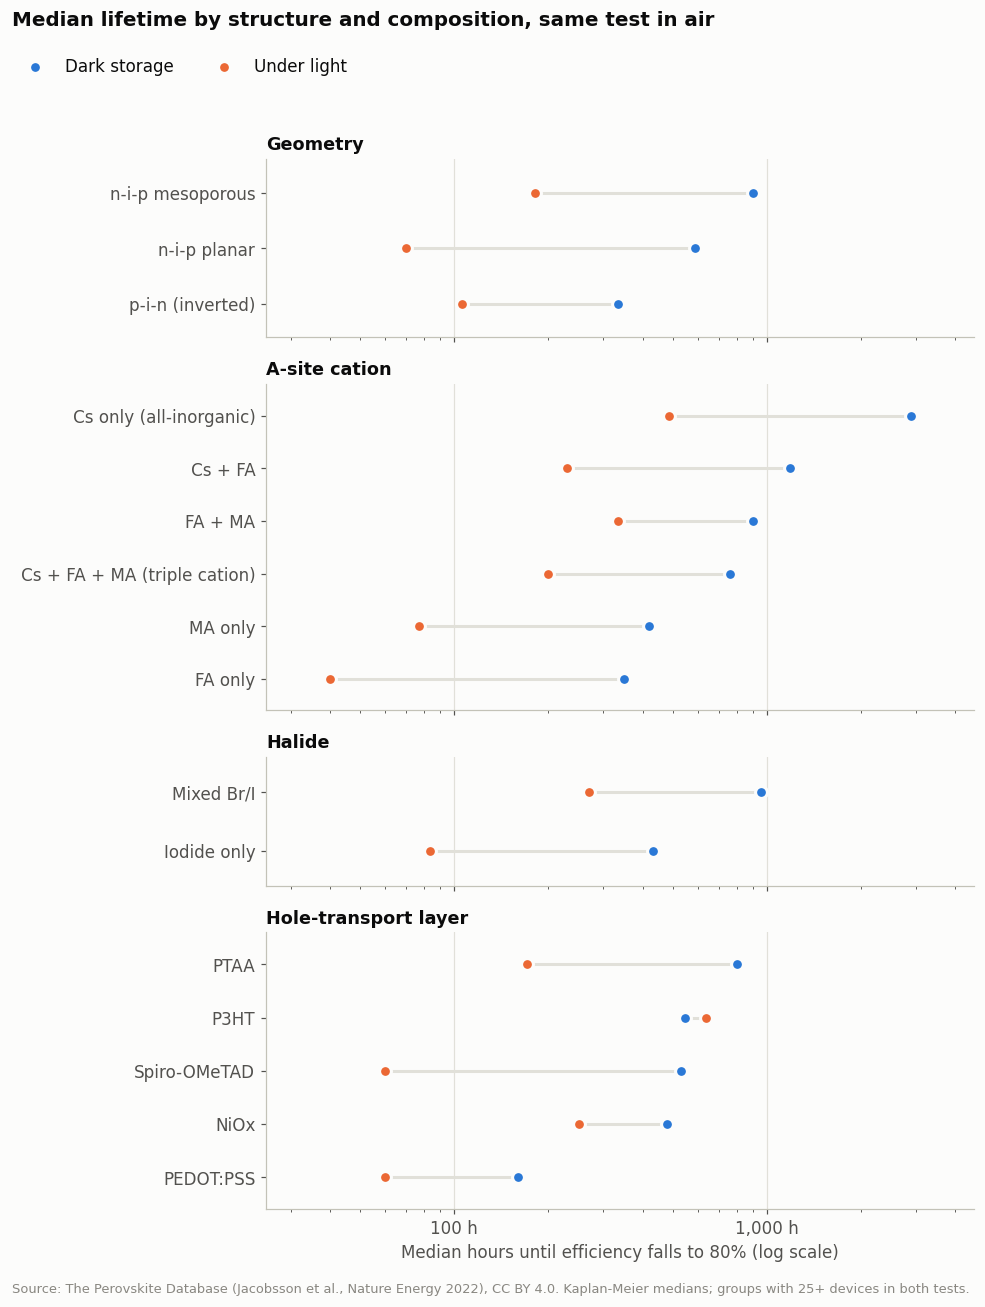

In [10]:
pr = pd.DataFrame(plot_rows)
counts = pr["section"].value_counts()
sections = [s for s in GROUPINGS.values() if counts.get(s, 0) >= 2]   # a one-row section has nothing to compare
pr = pr[pr["section"].isin(sections)]
fig, axes = plt.subplots(len(sections), 1, figsize=(9, 0.5 * len(pr) + 0.9 * len(sections)), sharex=True,
                         gridspec_kw={"height_ratios": [counts[s] + 0.6 for s in sections]})
axes = np.atleast_1d(axes)
for ax, section in zip(axes, sections):
    part = pr[pr["section"] == section].sort_values("dark")
    y = np.arange(len(part))
    ax.hlines(y, part["light"], part["dark"], color=GRID, lw=2)
    ax.scatter(part["dark"], y, s=60, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3, label="Dark storage")
    ax.scatter(part["light"], y, s=60, color=ORANGE, edgecolor=SURFACE, linewidth=2, zorder=3, label="Under light")
    ax.set_yticks(y, part["group"])
    ax.set_ylim(-0.6, len(part) - 0.4)
    ax.set_title(section, fontsize=11.5)
    ax.grid(axis="y", visible=False)
    ax.set_xscale("log")
axes[-1].set_xlim(pr[["dark", "light"]].min().min() / 1.6, pr[["dark", "light"]].max().max() * 1.6)
axes[-1].set_xlabel("Median hours until efficiency falls to 80% (log scale)")
axes[-1].xaxis.set_major_formatter(lambda v, _: f"{v:,.0f} h")
fig.suptitle("Median lifetime by structure and composition, same test in air", x=0.01, y=0.995, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=2, loc="upper left", bbox_to_anchor=(0.0, 0.97))
fig.text(0.01, -0.01, SOURCE + ". Kaplan-Meier medians; groups with 25+ devices in both tests.",
         fontsize=8.5, color=MUTED)
save(fig, "8_lifetime_by_group")

### What a survival curve looks like

These are the Kaplan–Meier curves behind the light-soaking medians, split by A-site cation. Each curve starts at 100% of devices still above 80% efficiency and steps down whenever a device fails. Where a curve crosses the 50% line is that group's median lifetime.

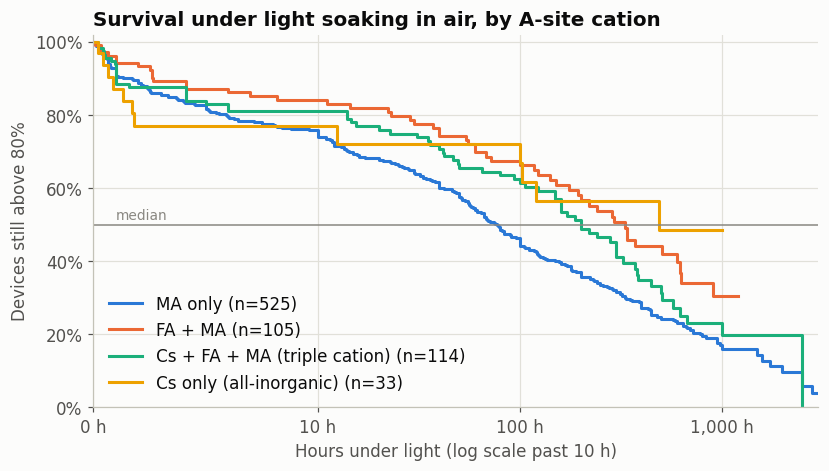

In [11]:
light_set = surv[LIGHT]
order = [g for g in ["MA only", "FA + MA", "Cs + FA + MA (triple cation)", "Cs only (all-inorganic)"]
         if (light_set["a_site"] == g).sum() >= MIN_N]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for group, color in zip(order, [BLUE, ORANGE, "#1baf7a", "#eda100"]):   # categorical slots 1-4, fixed order
    sub = light_set[light_set["a_site"] == group]
    km = KaplanMeierFitter().fit(sub["time"], sub["event"])
    sf = km.survival_function_.iloc[:, 0]
    ax.step(sf.index, sf.values * 100, where="post", color=color, lw=2, label=f"{group} (n={len(sub)})")
ax.axhline(50, color=MUTED, lw=1)
ax.text(1, 51.5, "median", color=MUTED, fontsize=9)
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(0, 3000)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f} h")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_ylim(0, 102)
ax.set_xlabel("Hours under light (log scale past 10 h)")
ax.set_ylabel("Devices still above 80%")
ax.set_title("Survival under light soaking in air, by A-site cation")
ax.legend(frameon=False, loc="lower left")
save(fig, "9_survival_curves_light")

**Reading these results.** The patterns line up with known chemistry. Pure MA and pure FA perovskites are the least stable, consistent with MA's volatility and pure FAPbI₃'s tendency to slip into its inactive yellow phase. Mixed-cation and Cs-containing compositions last longer. Tin degrades fast, consistent with Sn²⁺ oxidizing to Sn⁴⁺. PEDOT:PSS, which is acidic and hygroscopic, performs worst in dark storage.

**Two cautions.** First, these are *associations*, not controlled experiments. Mixed-cation recipes caught on later, so some of their advantage may reflect better processing over time rather than chemistry alone. Second, the ranking can change between dark storage and light, which is exactly why test conditions have to be reported.

## 6. Can we improve the numbers?

Three ideas, each tested the same way as Part 1: five rounds, each holding out a different fifth of the *papers*.

1. **Richer features:** give the model the structure and composition groups above, plus the type of test (ISOS category).
2. **Separate models per test type:** train one model only on dark-storage tests and one only on light tests.
3. **Use the censored devices:** a *random survival forest* is a random forest that can learn from "still working at hour X." It trains on all ~7,400 tested devices instead of only the ~1,800 with a T80.

**A new score: the C-index.** R² only works when every device has a lifetime number, so survival models are graded with the **concordance index**. Pick two devices at random: how often does the model correctly say which one lasts longer? **0.5 is a coin flip, 1.0 is always right.** It counts censored devices correctly: a device known to have survived 1,000 h is known to outlast one that failed at 200 h.

In [12]:
surv["encapsulated_str"] = surv["encapsulated"].map({True: "yes", False: "no/unknown"})
BASE = ["architecture", "composition", "atmosphere", "light_condition", "bias", "encapsulated_str"]
RICH = BASE + ["dimensionality", "geometry", "a_site", "halide", "b_site", "htl", "test_type"]
NUMS = [c for c in ["temp_max_c", "rh_pct", "light_mw", "pce_initial", "band_gap", "area_cm2", "year"]
        if surv[c].notna().mean() >= 0.05]

def make_prep(cats):
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10,
                                                    sparse_output=False), cats),
                              ("num", SimpleImputer(strategy="median", add_indicator=True), NUMS)])
def make_forest(cats):
    return Pipeline([("prep", make_prep(cats)),
                     ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1,
                                                     random_state=RANDOM_STATE))])

has_t80 = surv["outcome_source"].eq("reported T80").values
ev, tm, papers = surv["event"].values, surv["time"].values, surv["paper"].values
scores = {}
def add(name, c=None, r2=None):
    s = scores.setdefault(name, {"C": [], "R2": []})
    if c is not None: s["C"].append(c)
    if r2 is not None: s["R2"].append(r2)

for fold, (tr, te) in enumerate(GroupKFold(5).split(surv, groups=papers)):
    tr80, te80 = tr[has_t80[tr]], te[has_t80[te]]
    for name, cats in [("Random forest, Part 1 features (T80 devices only)", BASE),
                       ("Random forest + structure, composition, test type (T80 devices only)", RICH)]:
        cols = cats + NUMS
        model = make_forest(cats).fit(surv.iloc[tr80][cols], np.log10(tm[tr80]))
        c = concordance_index_censored(ev[te], tm[te], -model.predict(surv.iloc[te][cols]))[0]
        r2 = r2_score(np.log10(tm[te80]), model.predict(surv.iloc[te80][cols]))
        add(name, c, r2)
    prep = make_prep(RICH).fit(surv.iloc[tr][RICH + NUMS])
    y_tr = np.array(list(zip(ev[tr], tm[tr])), dtype=[("event", bool), ("time", float)])
    rsf = RandomSurvivalForest(n_estimators=200, min_samples_leaf=10, max_features="sqrt", n_jobs=-1,
                               random_state=RANDOM_STATE).fit(prep.transform(surv.iloc[tr][RICH + NUMS]), y_tr)
    add("Random survival forest, all tested devices",
        concordance_index_censored(ev[te], tm[te], rsf.predict(prep.transform(surv.iloc[te][RICH + NUMS])))[0])
    print(f"round {fold + 1} of 5 done")

improve = pd.DataFrame({name: {"C-index": np.mean(s["C"]), "C-index spread": np.std(s["C"]),
                               "R² (devices with a T80)": np.mean(s["R2"]) if s["R2"] else np.nan,
                               "R² spread": np.std(s["R2"]) if s["R2"] else np.nan}
                        for name, s in scores.items()}).T
improve.style.format({"C-index": "{:.2f}", "C-index spread": "{:.3f}", "R² (devices with a T80)": "{:.2f}",
                      "R² spread": "{:.2f}"}, na_rep="–")

round 1 of 5 done


round 2 of 5 done


round 3 of 5 done


round 4 of 5 done


round 5 of 5 done


,C-index,C-index spread,R² (devices with a T80),R² spread
"Random forest, Part 1 features (T80 devices only)",0.64,0.011,0.14,0.04
"Random forest + structure, composition, test type (T80 devices only)",0.66,0.009,0.18,0.05
"Random survival forest, all tested devices",0.70,0.008,–,–


**Why Part 1's model scores a little differently here.** These rounds split the papers into slightly different groups than Part 1 did, so the same model lands at R² ≈ 0.14 here versus 0.12 there. The "spread" columns show how much scores move from one round to the next. Treat differences smaller than that as noise.

In [13]:
# Idea 2: separate models for each test type (T80 devices only), scored by R² on held-out papers
within = {}
for label, mask in [("Dark storage only", surv["test_type"].eq(TEST_TYPES["d1"])),
                    ("Light soaking only", surv["test_type"].eq(TEST_TYPES["l1"]))]:
    sub = surv[mask & surv["outcome_source"].eq("reported T80")]
    r2s = []
    for tr, te in GroupKFold(5).split(sub, groups=sub["paper"]):
        m = make_forest(RICH).fit(sub.iloc[tr][RICH + NUMS], np.log10(sub.iloc[tr]["time"]))
        r2s.append(r2_score(np.log10(sub.iloc[te]["time"]), m.predict(sub.iloc[te][RICH + NUMS])))
    within[label] = {"devices": len(sub), "R²": np.mean(r2s), "R² spread": np.std(r2s)}
pd.DataFrame(within).T.style.format({"devices": "{:,.0f}", "R²": "{:.2f}", "R² spread": "{:.2f}"})

,devices,R²,R² spread
Dark storage only,"1,099",0.09,0.08
Light soaking only,425,-0.02,0.14


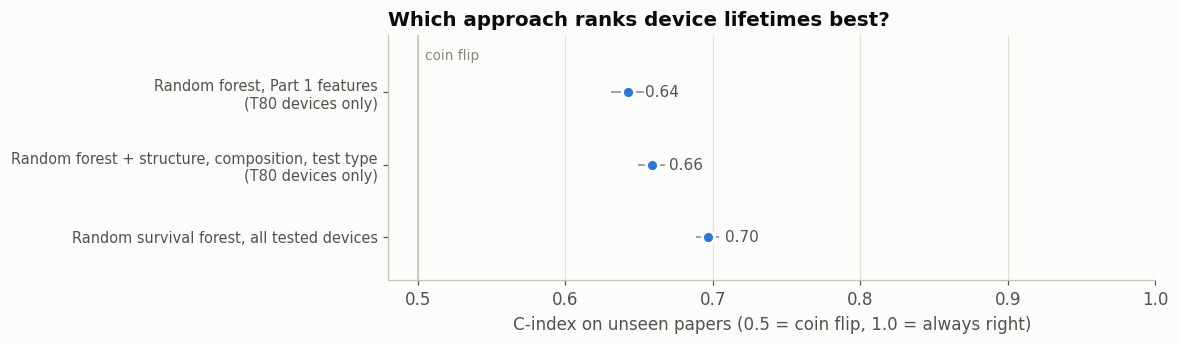

In [14]:
fig, ax = plt.subplots(figsize=(9, 2.9))
names = list(improve.index)
y = np.arange(len(names))[::-1]
ax.errorbar(improve["C-index"], y, xerr=improve["C-index spread"], fmt="o", ms=8, color=BLUE,
            mec=SURFACE, mew=2, ecolor=MUTED, elinewidth=1, capsize=0)
for yi, v in zip(y, improve["C-index"]):
    ax.text(v + 0.012, yi, f"{v:.2f}", va="center", fontsize=10, color=INK_2)
ax.axvline(0.5, color="#c3c2b7", lw=1)
ax.text(0.505, y.max() + 0.45, "coin flip", fontsize=9, color=MUTED)
ax.set_yticks(y, [n.replace(" (T80", "\n(T80") for n in names], fontsize=9.5)
ax.set_xlim(0.48, 1.0)
ax.set_ylim(-0.6, y.max() + 0.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("C-index on unseen papers (0.5 = coin flip, 1.0 = always right)")
ax.set_title("Which approach ranks device lifetimes best?")
save(fig, "10_model_comparison")

## 7. What would actually move these numbers

Better statistics helped. Using the censored devices raised the C-index clearly (0.64 to 0.70, well beyond the round-to-round spread), while adding structure and composition features gave only a small gain. But no approach gets anywhere near 1.0, and splitting by test type made R² *worse*, because each slice has less data and the leftover variation is mostly lab-to-lab differences the database doesn't capture. The ceiling here is set by the data, not the algorithm. Raising it would take:

- **Full decay curves, not single numbers.** A T80 or an end value throws away the shape of the curve: burn-in, steady decline, or sudden failure. Publishing the raw time series, or uploading it to the database, would let models learn degradation itself.
- **Always reporting "% kept at time X."** That turns a blank T80 into usable censored data.
- **Standard tests that resemble use.** ISOS-L-2 (light plus 65–85 °C) and damp heat instead of dark shelf storage, so labs can be compared directly.
- **Reporting the hidden variables.** Encapsulation details, humidity, processing atmosphere, and how many devices were tested (not just the champion).
- **Newer data.** This snapshot ends around 2020. The LLM-extracted update to this database in NOMAD ([PERLA](https://arxiv.org/abs/2601.17807)) could show whether reporting has improved since.

From a commercialization point of view, these steps are what turn "the paper says it's stable" into a lifetime claim that a licensee, investor, or insurer can price.

In [15]:
mods = improve["C-index"]
s2 = {
    "c_index_part1_model": mods.iloc[0], "c_index_rich_features": mods.iloc[1], "c_index_survival_forest": mods.iloc[2],
    "r2_part1_model": improve.iloc[0]["R² (devices with a T80)"], "r2_rich_features": improve.iloc[1]["R² (devices with a T80)"],
    "r2_dark_only_model": within["Dark storage only"]["R²"], "r2_light_only_model": within["Light soaking only"]["R²"],
    "devices_used_survival": len(surv), "devices_used_t80_only": int(has_t80.sum()),
}
pd.Series(s2).to_csv("part2_summary.csv", header=["value"])
print(f"""
- Using every tested device ({s2['devices_used_survival']:,} instead of {s2['devices_used_t80_only']:,}) with a random survival forest
  raised the C-index from {s2['c_index_part1_model']:.2f} to {s2['c_index_survival_forest']:.2f}.
- Adding structure, composition and test type raised R² from {s2['r2_part1_model']:.2f} to {s2['r2_rich_features']:.2f},
  a small gain about the size of the round-to-round spread.
- Separate models per test type did worse (R² {s2['r2_dark_only_model']:.2f} dark, {s2['r2_light_only_model']:.2f} light).
""")


- Using every tested device (7,358 instead of 1,832) with a random survival forest
  raised the C-index from 0.64 to 0.70.
- Adding structure, composition and test type raised R² from 0.14 to 0.18,
  a small gain about the size of the round-to-round spread.
- Separate models per test type did worse (R² 0.09 dark, -0.02 light).

